In [ ]:
#init
!pip install geoplot
!pip install geopandas
!pip install geoplot.crs
import geopandas as gpd
import geoplot as gplt
import geoplot.crs as gcrs
import matplotlib.pyplot as plt


ERROR: Could not find a version that satisfies the requirement geoplot.crs (from versions: none)
ERROR: No matching distribution found for geoplot.crs


In [ ]:
nyc_boroughs = gpd.read_file(gplt.datasets.get_path('nyc_boroughs'))
nyc_collision_factors = gpd.read_file(gplt.datasets.get_path('nyc_collision_factors'))


proj = gcrs.AlbersEqualArea(central_latitude=40.7128, central_longitude=-74.0059)
fig = plt.figure(figsize=(10, 5))
ax1 = plt.subplot(121, projection=proj)
ax2 = plt.subplot(122, projection=proj)

gplt.kdeplot(
    nyc_collision_factors[
        nyc_collision_factors['CONTRIBUTING FACTOR VEHICLE 1'] == "Failure to Yield Right-of-Way"
    ],
    cmap='Reds',
    projection=proj,
    shade=True, thresh=0.05,
    clip=nyc_boroughs.geometry,
    ax=ax1
)
gplt.polyplot(nyc_boroughs, zorder=1, ax=ax1)
ax1.set_title("Failure to Yield Right-of-Way Crashes, 2016")

gplt.kdeplot(
    nyc_collision_factors[
        nyc_collision_factors['CONTRIBUTING FACTOR VEHICLE 1'] == "Lost Consciousness"
    ],
    cmap='Reds',
    projection=proj,
    shade=True, thresh=0.05,
    clip=nyc_boroughs.geometry,
    ax=ax2
)
gplt.polyplot(nyc_boroughs, zorder=1, ax=ax2)
ax2.set_title("Loss of Consciousness Crashes, 2016")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 882.2/882.2 kB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 101.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.3/22.3 MB 84.0 MB/s eta 0:00:00
ERROR: Could not find a version that satisfies the requirement geoplot.crs (from versions: none)
ERROR: No matching distribution found for geoplot.crs


HTTPError: HTTP Error 404: Not Found

In [ ]:
import geopandas as gpd
import geoplot as gplt
import geoplot.crs as gcrs
import matplotlib.pyplot as plt

# load the data
nyc_boroughs = gpd.read_file(gplt.datasets.get_path('nyc_boroughs'))
nyc_fatal_collisions = gpd.read_file(gplt.datasets.get_path('nyc_fatal_collisions'))
nyc_injurious_collisions = gpd.read_file(gplt.datasets.get_path('nyc_injurious_collisions'))


fig = plt.figure(figsize=(10, 5))
proj = gcrs.AlbersEqualArea(central_latitude=40.7128, central_longitude=-74.0059)
ax1 = plt.subplot(121, projection=proj)
ax2 = plt.subplot(122, projection=proj)

ax1 = gplt.pointplot(
    nyc_fatal_collisions, projection=proj,
    hue='BOROUGH', cmap='Set1',
    edgecolor='white', linewidth=0.5,
    scale='NUMBER OF PERSONS KILLED', limits=(8, 24),
    legend=True, legend_var='scale',
    legend_kwargs={'loc': 'upper left', 'markeredgecolor': 'black'},
    legend_values=[2, 1], legend_labels=['2 Fatalities', '1 Fatality'],
    ax=ax1
)
gplt.polyplot(nyc_boroughs, ax=ax1)
ax1.set_title("Fatal Crashes in New York City, 2016")

gplt.pointplot(
    nyc_injurious_collisions, projection=proj,
    hue='BOROUGH', cmap='Set1',
    edgecolor='white', linewidth=0.5,
    scale='NUMBER OF PERSONS INJURED', limits=(4, 20),
    legend=True, legend_var='scale',
    legend_kwargs={'loc': 'upper left', 'markeredgecolor': 'black'},
    legend_values=[20, 15, 10, 5, 1],
    legend_labels=['20 Injuries', '15 Injuries', '10 Injuries', '5 Injuries', '1 Injury'],
    ax=ax2
)
gplt.polyplot(nyc_boroughs, ax=ax2, projection=proj)
ax2.set_title("Injurious Crashes in New York City, 2016")

HTTPError: HTTP Error 404: Not Found

Text(0.5, 1.0, 'Streets in Washington DC by Average Daily Traffic, 2015')

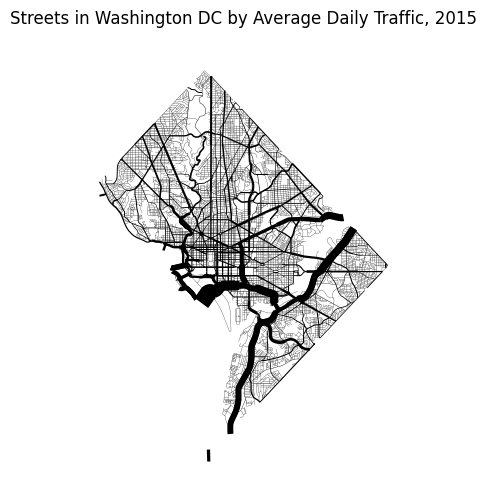

In [ ]:
import geopandas as gpd
import geoplot as gplt
import geoplot.crs as gcrs
import matplotlib.pyplot as plt

dc_roads = gpd.read_file(gplt.datasets.get_path('dc_roads'))

gplt.sankey(
    dc_roads, projection=gcrs.AlbersEqualArea(),
    scale='aadt', limits=(0.1, 10), color='black'
)

plt.title("Streets in Washington DC by Average Daily Traffic, 2015")

/usr/local/lib/python3.12/dist-packages/geoplot/geoplot.py:1304: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(


Text(0.5, 1.0, 'Boston AirBnB Locations, 2016')

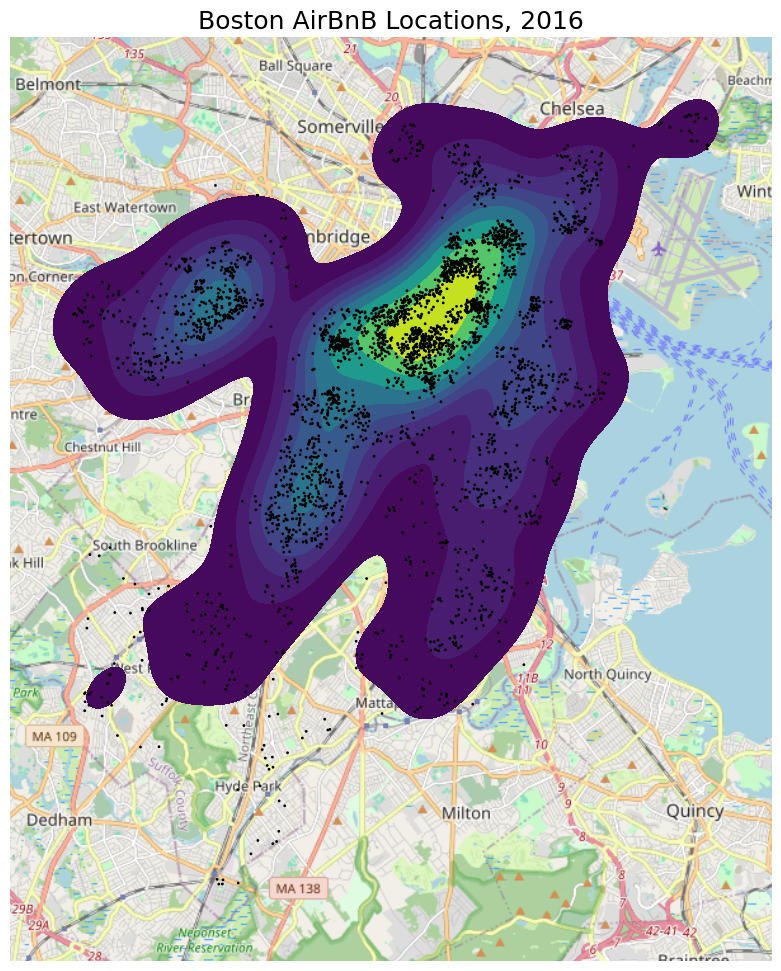

In [ ]:
import geopandas as gpd
import geoplot as gplt
import geoplot.crs as gcrs
import matplotlib.pyplot as plt

boston_airbnb_listings = gpd.read_file(gplt.datasets.get_path('boston_airbnb_listings'))

ax = gplt.kdeplot(
    boston_airbnb_listings, cmap='viridis', projection=gcrs.WebMercator(), figsize=(12, 12),
    shade=True
)
gplt.pointplot(boston_airbnb_listings, s=1, color='black', ax=ax)
gplt.webmap(boston_airbnb_listings, ax=ax)
plt.title('Boston AirBnB Locations, 2016', fontsize=18)

### 1. Loading a CSV file with Latitude and Longitude

In [ ]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

# Assuming your CSV has 'latitude' and 'longitude' columns
# Replace 'your_data.csv' with the path to your CSV file
df = pd.read_csv('your_data.csv')

# Convert DataFrame to GeoDataFrame
# First, create a 'geometry' column from 'longitude' and 'latitude'
df['geometry'] = df.apply(lambda row: Point(row['longitude'], row['latitude']), axis=1)

# Specify the Coordinate Reference System (CRS). WGS84 (EPSG:4326) is common for lat/lon.
geodf_from_csv = gpd.GeoDataFrame(df, geometry='geometry', crs="EPSG:4326")

print("GeoDataFrame from CSV head:")
display(geodf_from_csv.head())

FileNotFoundError: [Errno 2] No such file or directory: 'your_data.csv'

### 2. Loading GeoJSON or Shapefile

In [ ]:
import geopandas as gpd

# For a GeoJSON file
# Replace 'your_geojson.geojson' with the path to your GeoJSON file
geodf_geojson = gpd.read_file('your_geojson.geojson')

print("GeoDataFrame from GeoJSON head:")
display(geodf_geojson.head())

# For a Shapefile
# Replace 'your_shapefile.shp' with the path to your Shapefile
# (ensure all associated files like .dbf, .shx are in the same directory)
geodf_shapefile = gpd.read_file('your_shapefile.shp')

print("GeoDataFrame from Shapefile head:")
display(geodf_shapefile.head())

DataSourceError: your_geojson.geojson: No such file or directory

Remember to replace the placeholder file paths (`'your_data.csv'`, `'your_geojson.geojson'`, `'your_shapefile.shp'`) with the actual paths to your data files.

In [ ]:
import folium
from folium.plugins import HeatMap
import pandas as pd

# Load your data (replace with your actual file path or DataFrame)
df = pd.read_csv('https://raw.githubusercontent.com/camthornber/ds410carcrash/6408a9d1ff5f78d484a8e9e55138c9698f3e77ce/sample_data_for_github.csv')

# Filter out rows with missing coordinates
df_clean = df[['Start_Lat', 'Start_Lng', 'State', 'City', 'Severity']].dropna()

df_clean = df_clean[df_clean['State'].isin(['PA'])]
#df_clean = df_clean[df_clean['Severity'].isin([4])]


# Create a base map centered around the mean location
center_lat = df_clean['Start_Lat'].mean()
center_lng = df_clean['Start_Lng'].mean()
base_map = folium.Map(location=[center_lat, center_lng], zoom_start=6)

# Add heat map layer
heat_data = df_clean[['Start_Lat', 'Start_Lng']].values.tolist()
HeatMap(heat_data, radius=10, blur=10).add_to(base_map)


base_map

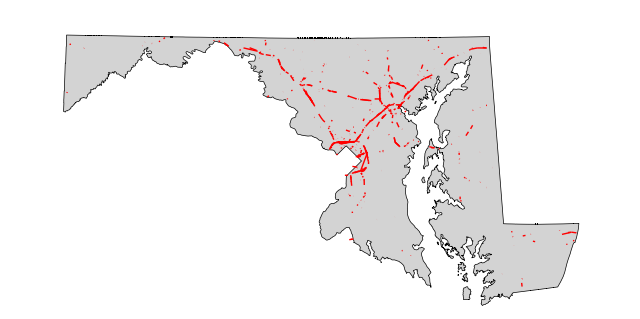

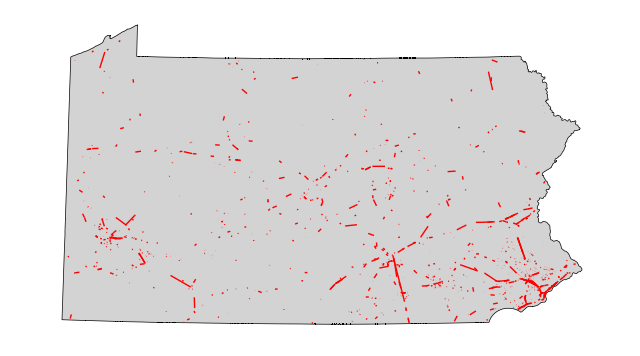

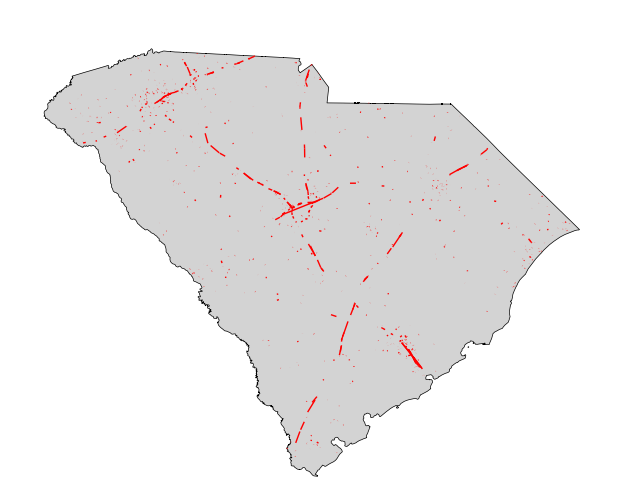

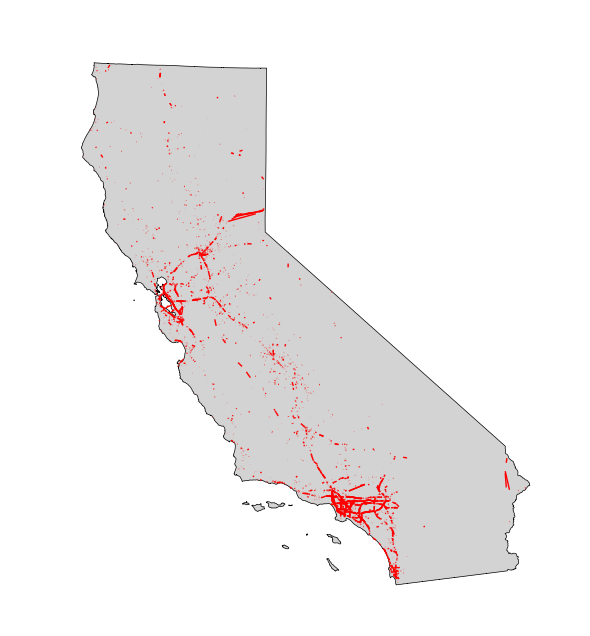

In [ ]:
import geopandas as gpd
import pandas as pd
import geoplot as gplt
import geoplot.crs as gcrs
import matplotlib.pyplot as plt

from shapely.geometry import LineString, Point

df = pd.read_csv('https://raw.githubusercontent.com/camthornber/ds410carcrash/6408a9d1ff5f78d484a8e9e55138c9698f3e77ce/sample_data_for_github.csv')

def snakey(my_state: str):
  #Create dataframe: only rows with end points can be used.
  df_startend = df[['Start_Lat', 'Start_Lng', 'End_Lng', 'End_Lat', 'State', 'City', 'Severity']].dropna()
  df_startend = df_startend[df_startend['State'].isin([my_state])] # <-- CHANGE STATE HERE

  #Create dataframe: use coordinates to create lines
  gdf = gpd.GeoDataFrame(
      df_startend,
      geometry = df_startend.apply(
      lambda r: LineString([
          (r['Start_Lng'], r['Start_Lat']),
          (r['End_Lng'], r['End_Lat'])
     ]),
      axis=1
  ),
      crs="EPSG:4326" #Coordinate Reference System WGS84: Latitude and longitude based coordinate system
  )

  #Shape files
  states = gpd.read_file("https://raw.githubusercontent.com/camthornber/ds410carcrash/407de6b22ab9441bbe646ad97543245b4f74812b/cb_2018_us_state_500k.shx")
  states = states.set_crs(epsg=4269)
  states_4326 = states.to_crs(epsg=4326)

  #Finding which state based on listed coordinates (for flexibility)
  center_lat = df_startend['Start_Lat'].mean()
  center_lng = df_startend['Start_Lng'].mean()
  center_point = Point(center_lng, center_lat)

  mask = states_4326.contains(center_point)
  bg_geom = states_4326[mask].iloc[[0]]

  #Adhere projection to state (makes the projection look better)
  def state_albers(state_geom_4326: gpd.GeoDataFrame):
     minx, miny, maxx, maxy = state_geom_4326.total_bounds
     central_lon = 0.5 * (minx + maxx)
     central_lat = 0.5 * (miny + maxy)
     p1 = miny + (maxy - miny) * 0.25
     p2 = miny + (maxy - miny) * 0.75
     return gcrs.AlbersEqualArea(
         central_longitude=central_lon,
         central_latitude=central_lat,
         standard_parallels=(p1, p2)
     )

  #Overlay the two maps
  proj = state_albers(bg_geom)
  fig, ax = plt.subplots(
      1, 1, figsize=(8, 8),
      subplot_kw={'projection': proj}
  )

  #Background projection
  gplt.polyplot(
      bg_geom,
      projection=proj,
      ax=ax,
      facecolor='lightgray',
      edgecolor='black',
      linewidth=0.5
  )

  #Foreground projection
  gplt.sankey(
      gdf, projection=proj, ax=ax,
      scale=None, limits=(0.1, 10), color='red'
  )

snakey('MD')
snakey('PA')
snakey('SC')
snakey('CA')

#--Katherine